In [ ]:
#Import libraries
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import os
import json
import seaborn as sns


In [12]:
# Reading dataset 
df = pd.read_csv('./CrisisMMD_v2.0/annotations/california_wildfires_final_data.tsv', sep='\t')

df.head(5)

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,image_damage,image_damage_conf,tweet_text,image_url,image_path
0,917791044158185473,917791044158185473_0,informative,1.0000,informative,0.6766,other_relevant_information,1.0000,other_relevant_information,0.6766,NaN,NaN,RT @Gizmodo: Wildfires raging through Northern...,http://pbs.twimg.com/media/DLyi_WYVYAApwNg.jpg,data_image/california_wildfires/10_10_2017/917...
1,917791130590183424,917791130590183424_0,informative,1.0000,informative,0.6667,infrastructure_and_utility_damage,1.0000,affected_individuals,0.6667,NaN,NaN,PHOTOS: Deadly wildfires rage in California ht...,http://pbs.twimg.com/media/DLymKm9UMAAu0qw.jpg,data_image/california_wildfires/10_10_2017/917...
2,917791291823591425,917791291823591425_0,informative,0.6813,informative,1.0000,other_relevant_information,0.6813,infrastructure_and_utility_damage,1.0000,severe_damage,1.0,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaaZV4AAjT7x.jpg,data_image/california_wildfires/10_10_2017/917...
3,917791291823591425,917791291823591425_1,informative,0.6813,not_informative,1.0000,other_relevant_information,0.6813,not_humanitarian,1.0000,NaN,NaN,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaZXUMAABAEZ.jpg,data_image/california_wildfires/10_10_2017/917...
4,917792092100988929,917792092100988929_0,informative,0.6727,informative,0.6612,other_relevant_information,0.6727,infrastructure_and_utility_damage,0.6612,severe_damage,1.0,RT @TIME: California's raging wildfires as you...,http://pbs.twimg.com/media/DLwNe-NXUAE0XCw.jpg,data_image/california_wildfires/10_10_2017/917...


In [13]:
# merged all tsv file into dataframe with extra label "diaster_label" for better preprocessing 

base_path = './CrisisMMD_v2.0'
annotations_dir = os.path.join(base_path, 'annotations')

all_dataframes = []

for filename in os.listdir(annotations_dir):
    if filename.endswith('.tsv') and not filename.startswith('._'):
        file_path = os.path.join(annotations_dir, filename)
        
        temp_df = pd.read_csv(file_path, sep='\t')
        
        disaster_label = filename.replace('_final_data.tsv', '')
        temp_df['disaster_type'] = disaster_label
        
        all_dataframes.append(temp_df)

master_df = pd.concat(all_dataframes, ignore_index=True)

print(f"Total rows merged: {len(master_df)}")
print(master_df['disaster_type'].value_counts())

Total rows merged: 18082
disaster_type
hurricane_maria         4556
hurricane_irma          4504
hurricane_harvey        4434
california_wildfires    1589
mexico_earthquake       1380
srilanka_floods         1022
iraq_iran_earthquake     597
Name: count, dtype: int64


In [14]:
master_df.head(5)

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,image_damage,image_damage_conf,tweet_text,image_url,image_path,disaster_type
0,917791044158185473,917791044158185473_0,informative,1.0000,informative,0.6766,other_relevant_information,1.0000,other_relevant_information,0.6766,NaN,NaN,RT @Gizmodo: Wildfires raging through Northern...,http://pbs.twimg.com/media/DLyi_WYVYAApwNg.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires
1,917791130590183424,917791130590183424_0,informative,1.0000,informative,0.6667,infrastructure_and_utility_damage,1.0000,affected_individuals,0.6667,NaN,NaN,PHOTOS: Deadly wildfires rage in California ht...,http://pbs.twimg.com/media/DLymKm9UMAAu0qw.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires
2,917791291823591425,917791291823591425_0,informative,0.6813,informative,1.0000,other_relevant_information,0.6813,infrastructure_and_utility_damage,1.0000,severe_damage,1.0,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaaZV4AAjT7x.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires
3,917791291823591425,917791291823591425_1,informative,0.6813,not_informative,1.0000,other_relevant_information,0.6813,not_humanitarian,1.0000,NaN,NaN,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaZXUMAABAEZ.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires
4,917792092100988929,917792092100988929_0,informative,0.6727,informative,0.6612,other_relevant_information,0.6727,infrastructure_and_utility_damage,0.6612,severe_damage,1.0,RT @TIME: California's raging wildfires as you...,http://pbs.twimg.com/media/DLwNe-NXUAE0XCw.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires


Tweet Index: 45 | Event: california_wildfires
TEXT: RT @monizcardozo: California wildfires: Residents find devastation in Santa Rosa https://t.co/3fuGJ5lW3t https://t.co/hNuXFATeh8
LABEL (Text): other_relevant_information
url: http://pbs.twimg.com/media/DLy5u7IVwAAaO3e.jpg
path: data_image/california_wildfires/10_10_2017/917815168825995264_0.jpg
imaqge hash: dbb099e39597e6809d280a20d9c776f1
LABEL (Image): vehicle_damage





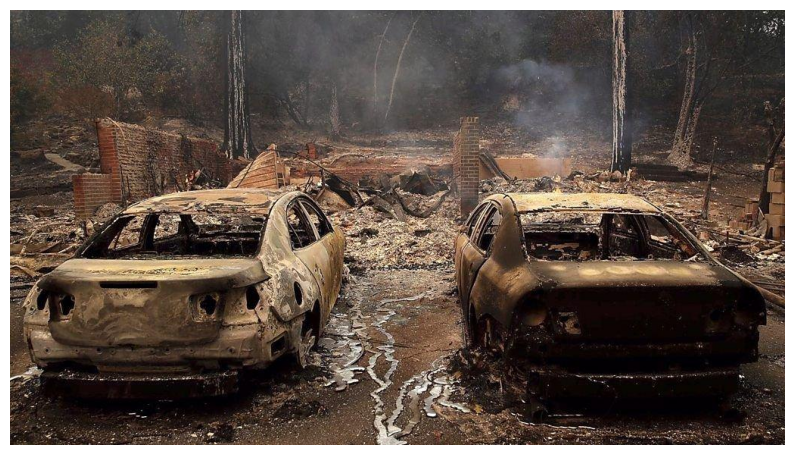

In [15]:
#Display text and tweet image
import hashlib

def display_tweet(df, index):

    if index >= len(df):
        print("Index out of range!")
        return

    row = df.iloc[index]
    
    tweet_text = row['tweet_text']
    img_rel_path = row['image_path']
    
    full_img_path = os.path.join(base_path, img_rel_path)

    def get_image_hash(fname):
        hash_md5 = hashlib.md5()
        try:
            with open(fname, "rb") as f:
                for chunk in iter(lambda: f.read(4096), b""):
                    hash_md5.update(chunk)
            return hash_md5.hexdigest()
        except FileNotFoundError:
            return None

    image_hash = get_image_hash(full_img_path)
    

    print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
    print(f"TEXT: {tweet_text}")
    print(f"LABEL (Text): {row['text_human']}")
    print(f"url: {row['image_url']}")
    print(f"path: {row['image_path']}")
    print(f"imaqge hash: {image_hash}")
    print(f"LABEL (Image): {row['image_human']}")
    print("\n\n")
    
    if os.path.exists(full_img_path):
        img = Image.open(full_img_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Error: image not found at {full_img_path}")

display_tweet(master_df, 45)

In [16]:
df["text_human"].unique()

<StringArray>
[            'other_relevant_information',
      'infrastructure_and_utility_damage',
                 'injured_or_dead_people',
                       'not_humanitarian',
                'missing_or_found_people',
 'rescue_volunteering_or_donation_effort',
                   'affected_individuals',
                         'vehicle_damage']
Length: 8, dtype: str

In [17]:
# Tweet Index: 43 | Event: california_wildfires
# TEXT: RT @TheAtlantic: Photos of California's destructive wildfires, via @TheAtlPhoto: https://t.co/mzYsQALqrl https://t.co/bWvczIJa2Z
# LABEL (Text): infrastructure_and_utility_damage
# LABEL (Text): http://pbs.twimg.com/media/DLy7qk8WsAI8aOA.jpg
# LABEL (Text): data_image/california_wildfires/10_10_2017/917815040962695168_1.jpg
# LABEL (Image): vehicle_damage

In [18]:
# Tweet Index: 45 | Event: california_wildfires
# TEXT: RT @monizcardozo: California wildfires: Residents find devastation in Santa Rosa https://t.co/3fuGJ5lW3t https://t.co/hNuXFATeh8
# LABEL (Text): other_relevant_information
# LABEL (Text): http://pbs.twimg.com/media/DLy5u7IVwAAaO3e.jpg
# LABEL (Text): data_image/california_wildfires/10_10_2017/917815168825995264_0.jpg
# LABEL (Image): vehicle_damage


Tweet Index: 45 | Event: california_wildfires
TEXT: RT @monizcardozo: California wildfires: Residents find devastation in Santa Rosa https://t.co/3fuGJ5lW3t https://t.co/hNuXFATeh8
LABEL (Text): other_relevant_information
URL: http://pbs.twimg.com/media/DLy5u7IVwAAaO3e.jpg
Path: data_image/california_wildfires/10_10_2017/917815168825995264_0.jpg
Image Hash: dbb099e39597e6809d280a20d9c776f1
LABEL (Image): vehicle_damage




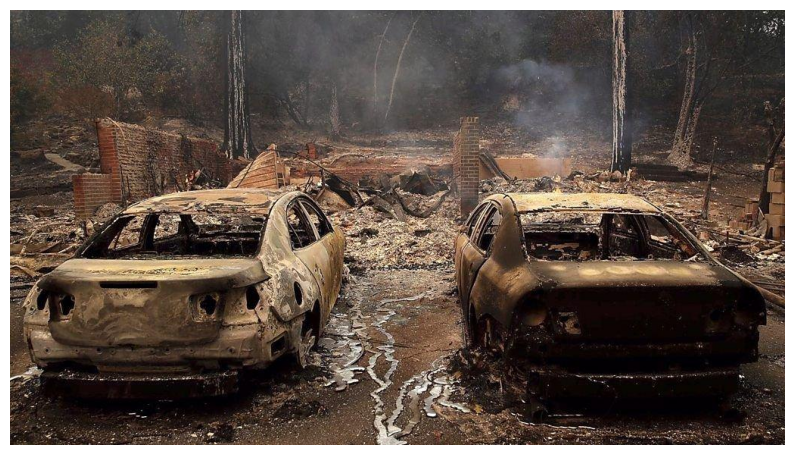

In [19]:
import hashlib

def get_image_hash(fname):
    hash_md5 = hashlib.md5()
    try:
        with open(fname, "rb") as f:
            for chunk in iter(lambda: f.read(4096), b""):
                hash_md5.update(chunk)
        return hash_md5.hexdigest()
    except FileNotFoundError:
        return None

def display_tweet(df, index):
    if index >= len(df):
        print("Index out of range!")
        return

    row = df.iloc[index]
    tweet_text = row['tweet_text']
    img_rel_path = row['image_path']
    
    full_img_path = os.path.join(base_path, img_rel_path)

    image_hash = get_image_hash(full_img_path)

    print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
    print(f"TEXT: {tweet_text}")
    print(f"LABEL (Text): {row['text_human']}")
    print(f"URL: {row['image_url']}")
    print(f"Path: {row['image_path']}")
    print(f"Image Hash: {image_hash}")
    print(f"LABEL (Image): {row['image_human']}")
    print("\n")
    
    if os.path.exists(full_img_path):
        img = Image.open(full_img_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Error: image not found at {full_img_path}")

display_tweet(master_df, 45)

Tweet Index: 43 | Event: california_wildfires
TEXT: RT @TheAtlantic: Photos of California's destructive wildfires, via @TheAtlPhoto: https://t.co/mzYsQALqrl https://t.co/bWvczIJa2Z
LABEL (Text): infrastructure_and_utility_damage
URL: http://pbs.twimg.com/media/DLy7qk8WsAI8aOA.jpg
Path: data_image/california_wildfires/10_10_2017/917815040962695168_1.jpg
Image Hash: 7a273053802f3fa5d462c8b1354bd2f0
LABEL (Image): vehicle_damage




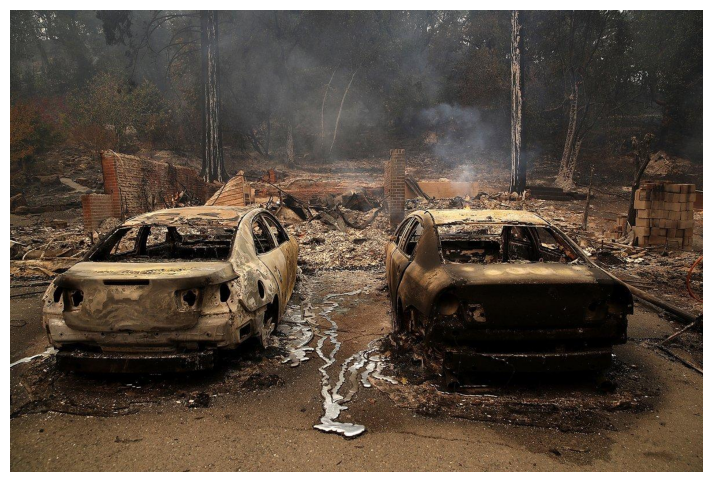

In [20]:
import hashlib

def get_image_hash(fname):
    hash_md5 = hashlib.md5()
    try:
        with open(fname, "rb") as f:
            for chunk in iter(lambda: f.read(4096), b""):
                hash_md5.update(chunk)
        return hash_md5.hexdigest()
    except FileNotFoundError:
        return None

def display_tweet(df, index):
    if index >= len(df):
        print("Index out of range!")
        return

    row = df.iloc[index]
    tweet_text = row['tweet_text']
    img_rel_path = row['image_path']
    
    full_img_path = os.path.join(base_path, img_rel_path)

    image_hash = get_image_hash(full_img_path)

    print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
    print(f"TEXT: {tweet_text}")
    print(f"LABEL (Text): {row['text_human']}")
    print(f"URL: {row['image_url']}")
    print(f"Path: {row['image_path']}")
    print(f"Image Hash: {image_hash}")
    print(f"LABEL (Image): {row['image_human']}")
    print("\n")
    
    if os.path.exists(full_img_path):
        img = Image.open(full_img_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Error: image not found at {full_img_path}")

display_tweet(master_df, 43)

In [21]:
def add_hash_column(df, base_path):
    hashes = []
    for _, row in df.iterrows():
        full_path = os.path.join(base_path, row["image_path"])
        hashes.append(get_image_hash(full_path))
    df["image_hash"] = hashes
    return df

master_df = add_hash_column(master_df, base_path)

# duplicate_hashes = (
#     master_df["image_hash"]
#     .value_counts()
#     .loc[lambda x: x > 1]
# )

# duplicate_df = master_df[
#     master_df["image_hash"].isin(duplicate_hashes.index)
# ]


# print(duplicate_df.head(5)) 
# print(f"Number of duplicate Images: {len(duplicate_df)}")


hash_counts = master_df["image_hash"].value_counts()

duplicate_hashes = hash_counts.loc[lambda x: x > 1]

duplicate_df = master_df[master_df["image_hash"].isin(duplicate_hashes.index)]

hash_dict = (
    duplicate_df.groupby("image_hash")
    .agg(
        count=("image_hash", "size"),
        events=("disaster_type", lambda x: list(x.unique()))
    )
    .to_dict(orient="index")
)

total_images = len(master_df)
unique_hashes_total = len(hash_counts)
num_unique_duplicates = len(duplicate_hashes)
total_duplicate_rows =  len(duplicate_df)

print(f"  Dataset Image Summary")
print(f"Total images in dataset:        {total_images}")
print(f"Total unique images (hashes):   {unique_hashes_total}")
print(f"Unique images that have copies: {num_unique_duplicates}")
print(f"Total rows that are duplicates: {total_duplicate_rows}")


def print_duplicate_hash(n):
    for i, (h, info) in enumerate(hash_dict.items()):
        if i < n:
            print(f"Hash: {h} | Count: {info['count']} | Events: {info['events']}")

print_duplicate_hash(5)

  Dataset Image Summary
Total images in dataset:        18082
Total unique images (hashes):   17777
Unique images that have copies: 181
Total rows that are duplicates: 486
Hash: 0122aaa0c9570986afd109c82d49a032 | Count: 2 | Events: ['iraq_iran_earthquake']
Hash: 018ffe193fd5f977f7066e3714027b10 | Count: 2 | Events: ['hurricane_irma']
Hash: 02cb3fdbe35760a7997d5e7ec4267073 | Count: 2 | Events: ['hurricane_maria']
Hash: 047dfd1d3e2993fe171f2d6f7e9a3fa4 | Count: 33 | Events: ['california_wildfires', 'hurricane_harvey', 'hurricane_irma', 'hurricane_maria', 'iraq_iran_earthquake', 'mexico_earthquake']
Hash: 07f26ecef0d326169f37dfe69826806f | Count: 2 | Events: ['hurricane_harvey']


In [22]:
event_duplicate_counts = duplicate_df.groupby("disaster_type").size().sort_values(ascending=False)

print("Duplicate images per event")
for event, count in event_duplicate_counts.items(): 
    print(f"{event:<30}: {count} duplicate rows")

Duplicate images per event
hurricane_maria               : 115 duplicate rows
hurricane_irma                : 100 duplicate rows
hurricane_harvey              : 92 duplicate rows
california_wildfires          : 71 duplicate rows
mexico_earthquake             : 60 duplicate rows
srilanka_floods               : 28 duplicate rows
iraq_iran_earthquake          : 20 duplicate rows


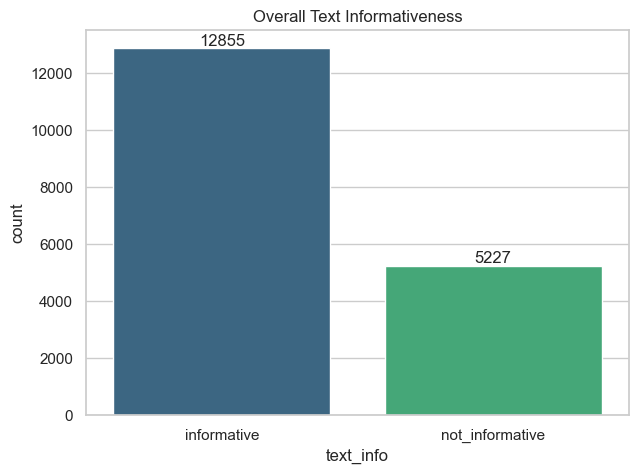

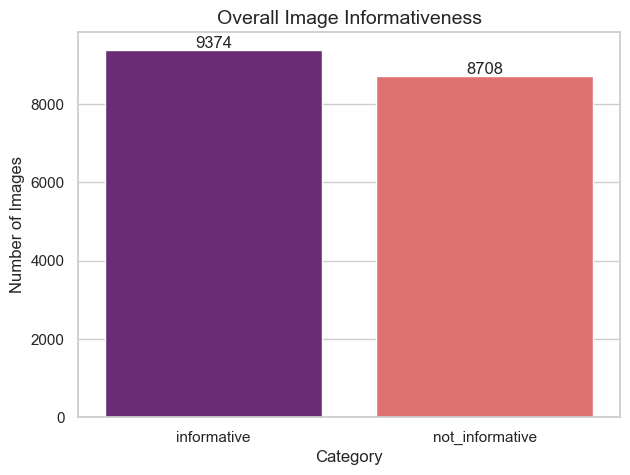

In [23]:
#text informativeness
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=master_df, x='text_info', hue='text_info', palette='viridis', legend=False)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Overall Text Informativeness')
plt.show()



#Image  informativesness
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=master_df, x='image_info', hue='image_info', palette='magma', legend=False)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Overall Image Informativeness', fontsize=14)
plt.xlabel('Category')
plt.ylabel('Number of Images')

plt.show()

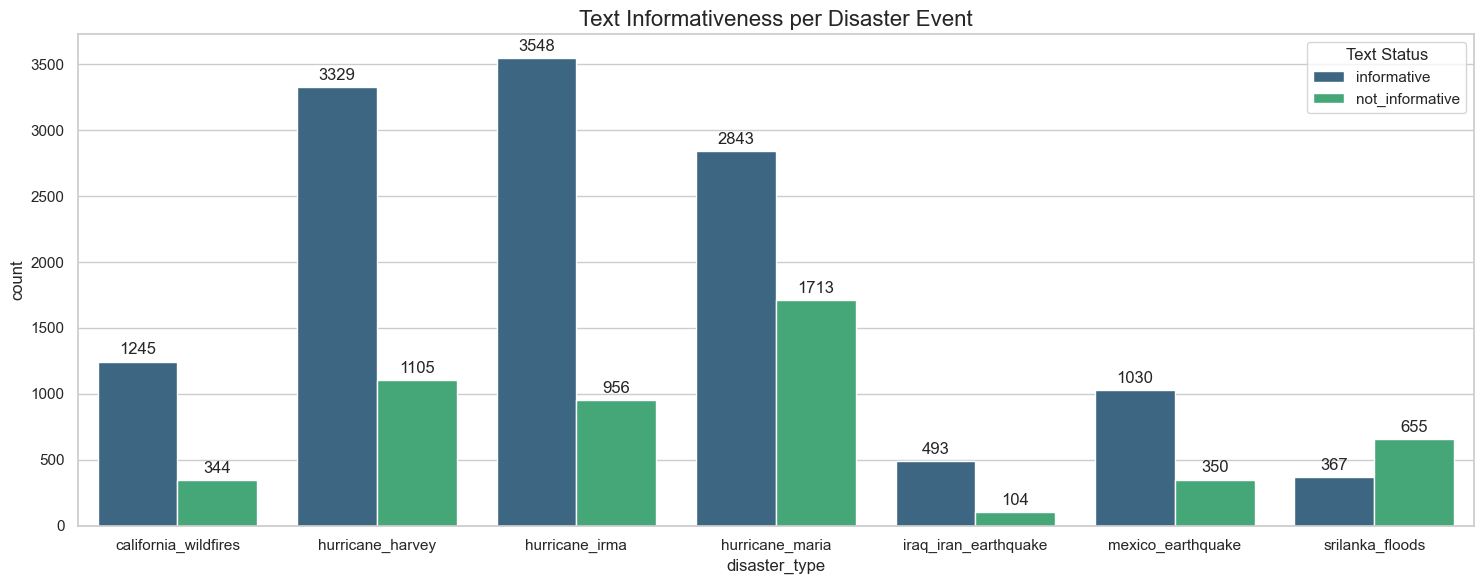

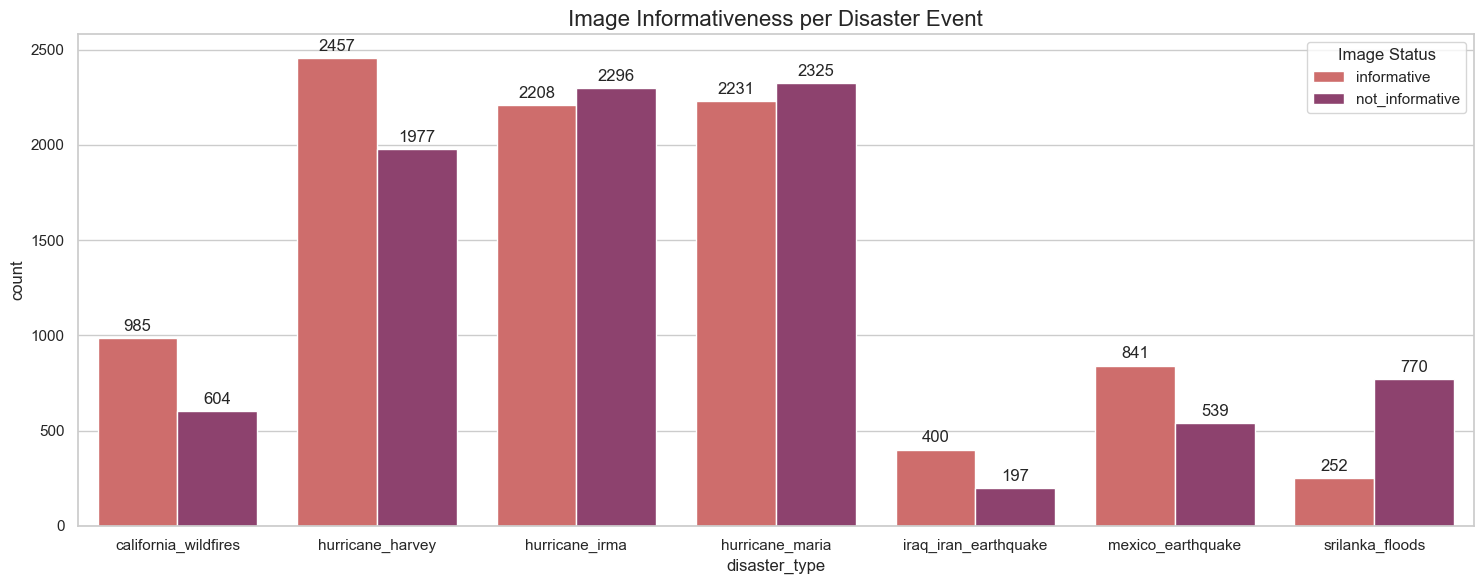

In [24]:

#text informativenss event wise
plt.figure(figsize=(15, 6))

ax = sns.countplot(data=master_df, x='disaster_type', hue='text_info', palette='viridis')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Text Informativeness per Disaster Event', fontsize=16)
plt.legend(title='Text Status', loc='upper right')

plt.tight_layout()
plt.show()


# image informativeness based on events
plt.figure(figsize=(15, 6))

ax = sns.countplot(data=master_df, x='disaster_type', hue='image_info', palette='flare')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Image Informativeness per Disaster Event', fontsize=16)
plt.legend(title='Image Status', loc='upper right')

plt.tight_layout()
plt.show()

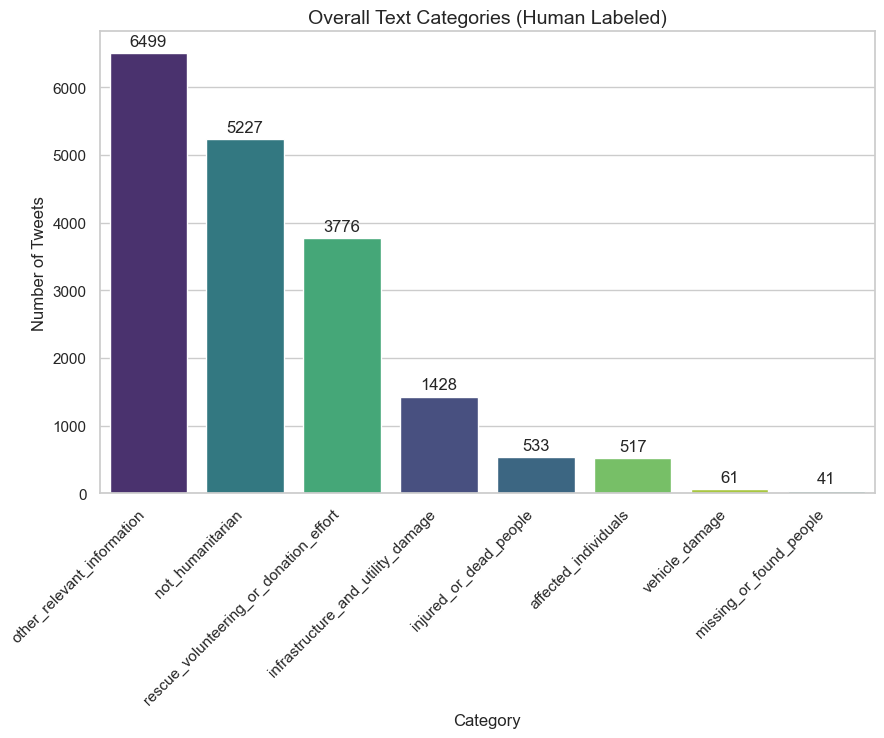

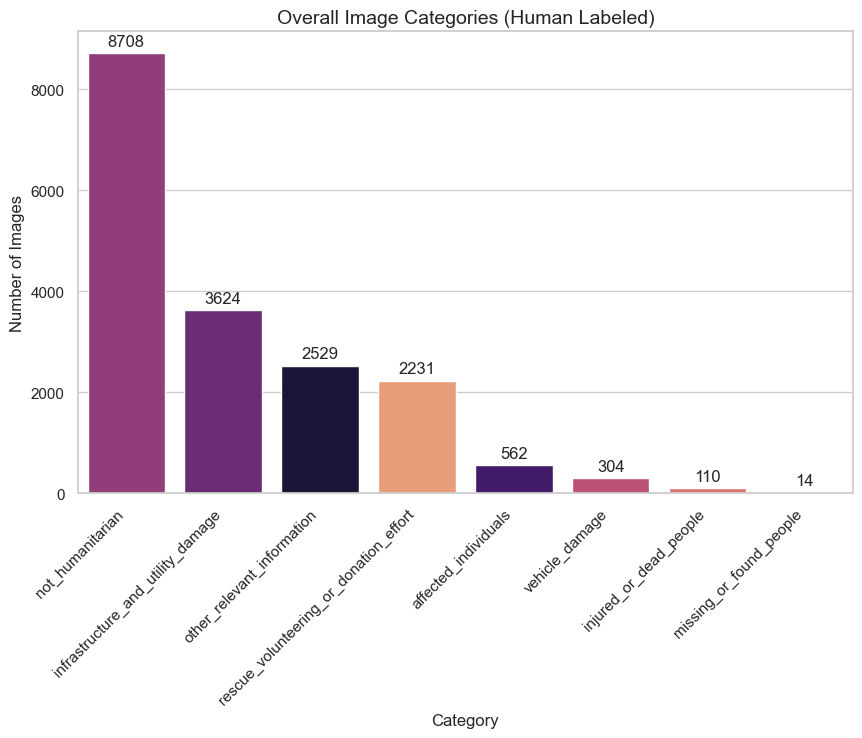

In [25]:
# text human labeled categories
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=master_df, 
    x='text_human', 
    hue='text_human', 
    palette='viridis', 
    legend=False,
    order=master_df['text_human'].value_counts().index
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Overall Text Categories (Human Labeled)', fontsize=14)
plt.xlabel('Category')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Number of Tweets')

plt.show()




# Image human labeled categories
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=master_df, 
    x='image_human', 
    hue='image_human', 
    palette='magma', 
    legend=False,
    order=master_df['image_human'].value_counts().index
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Overall Image Categories (Human Labeled)', fontsize=14)
plt.xlabel('Category')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Number of Images')

plt.show()

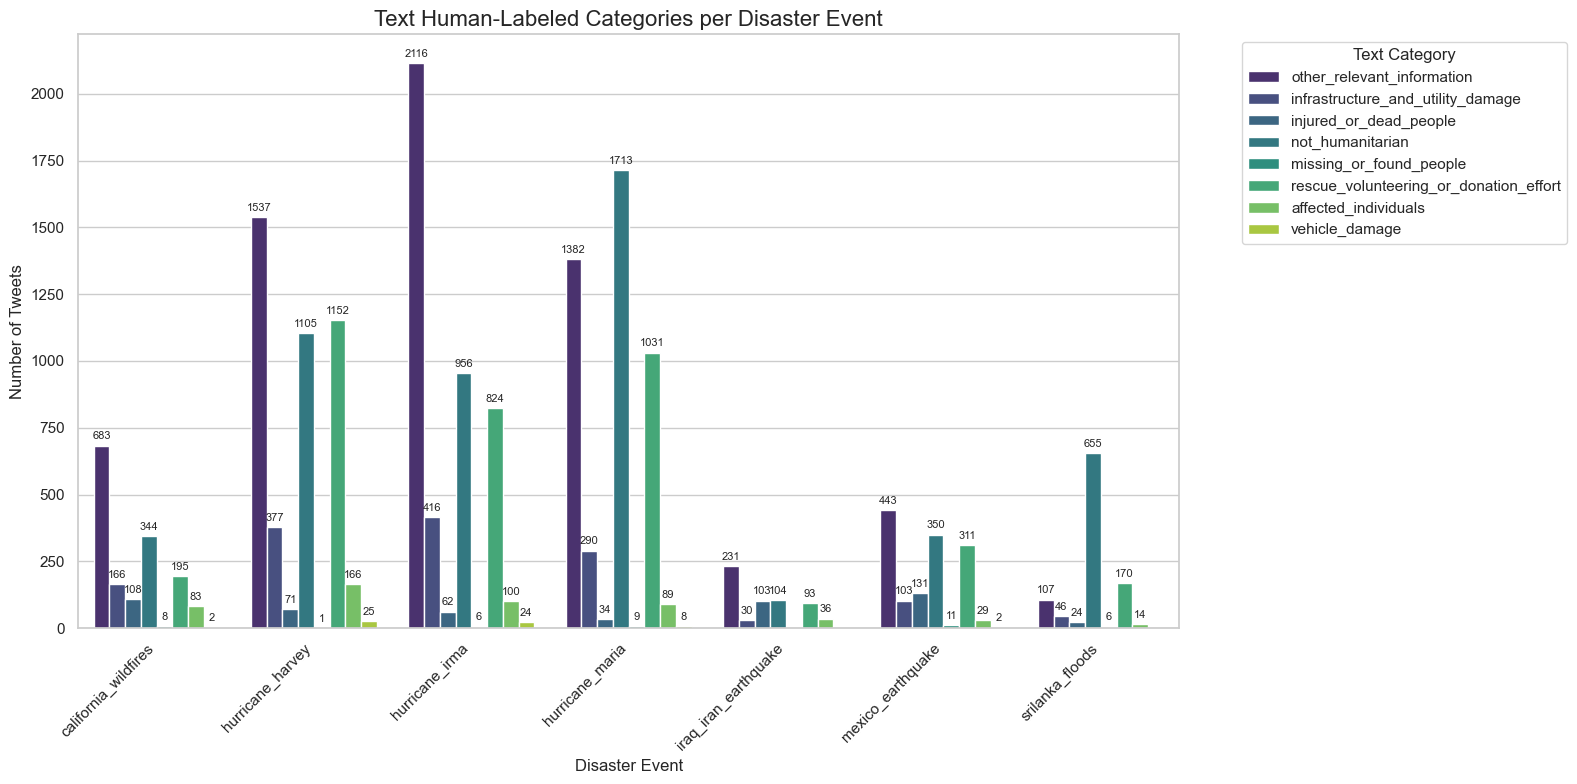

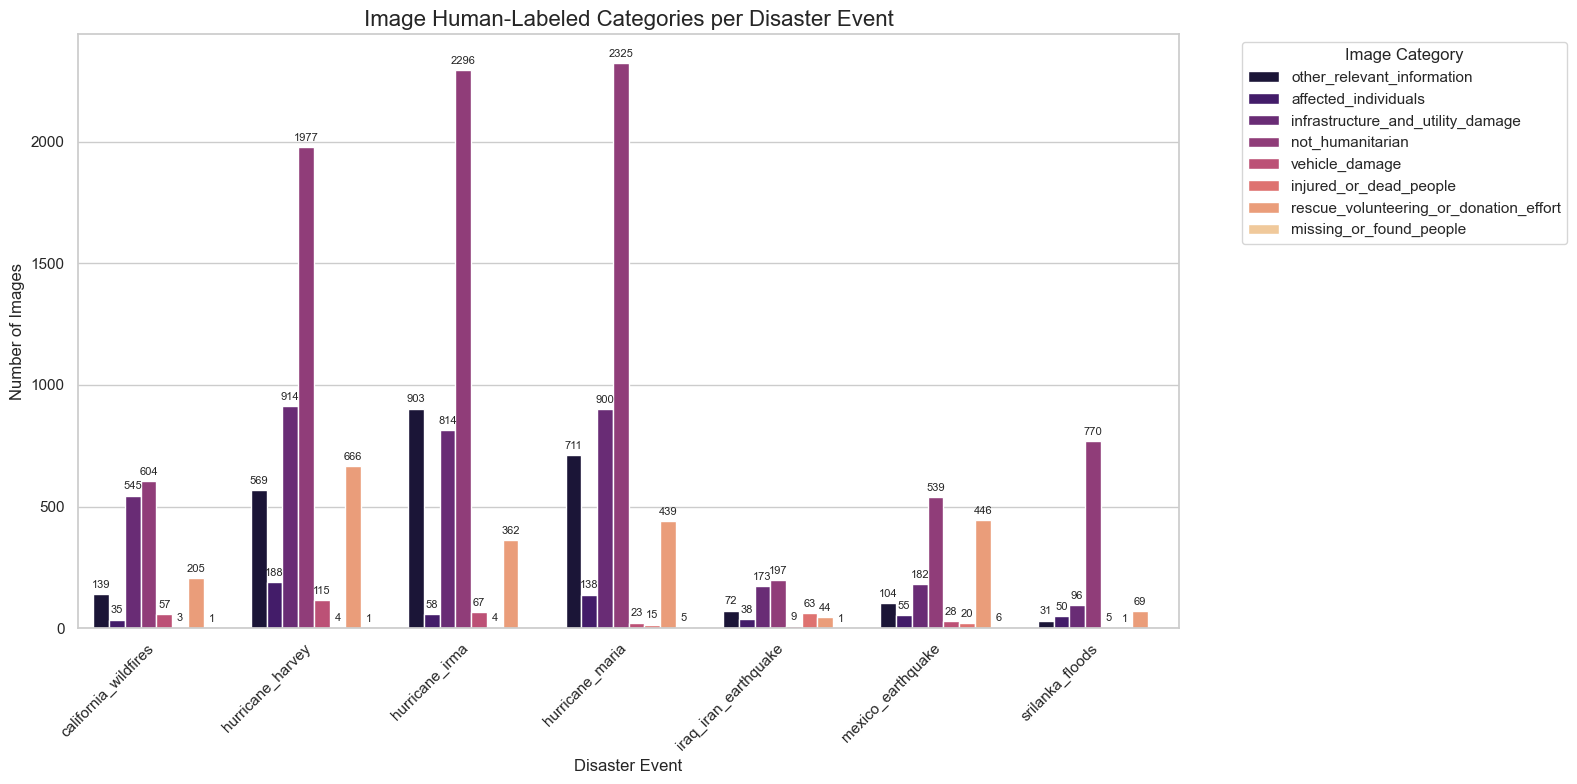

In [26]:
# Text human labeled categories event wise
plt.figure(figsize=(16, 8))

ax = sns.countplot(
    data=master_df, 
    x='disaster_type', 
    hue='text_human', 
    palette='viridis'
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)

plt.title('Text Human-Labeled Categories per Disaster Event', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Disaster Event')
plt.ylabel('Number of Tweets')

plt.legend(title='Text Category', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()



# Image human labeled categories event wise
plt.figure(figsize=(16, 8))
ax = sns.countplot(
    data=master_df, 
    x='disaster_type', 
    hue='image_human', 
    palette='magma'
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)

plt.title('Image Human-Labeled Categories per Disaster Event', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Disaster Event')
plt.ylabel('Number of Images')

plt.legend(title='Image Category', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

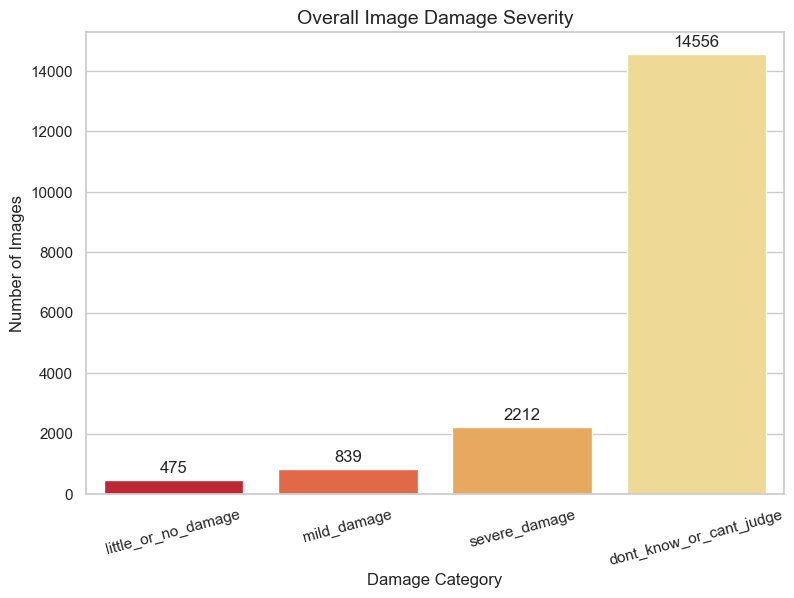

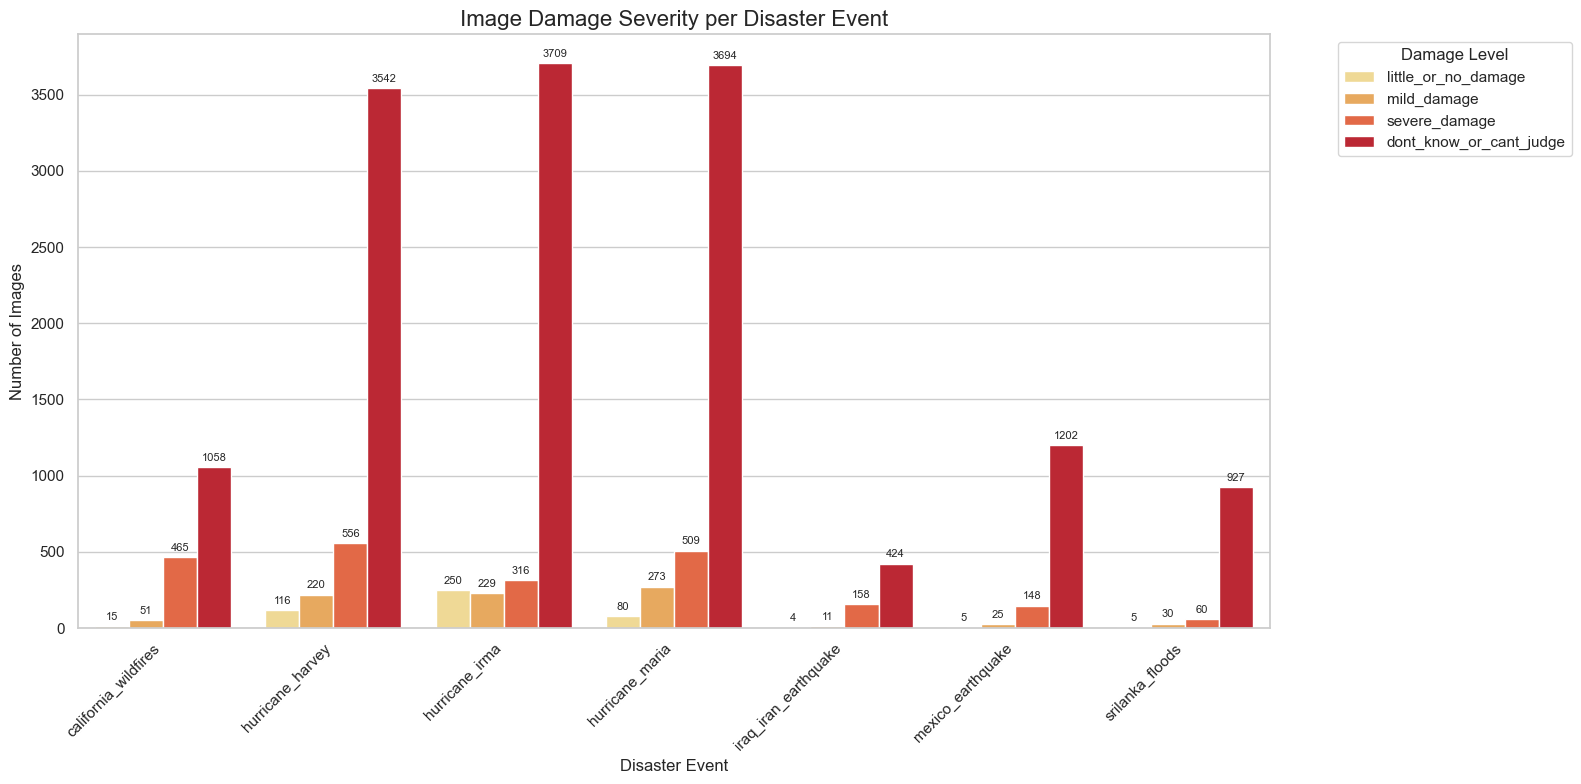

In [27]:
#fill nan with dont know category
master_df['image_damage'] = master_df['image_damage'].fillna('dont_know_or_cant_judge')

damage_order = ['little_or_no_damage', 'mild_damage', 'severe_damage', 'dont_know_or_cant_judge']

plt.figure(figsize=(9, 6))

ax = sns.countplot(
    data=master_df, 
    x='image_damage', 
    hue='image_damage', 
    palette='YlOrRd', 
    order=damage_order,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Overall Image Damage Severity', fontsize=14)
plt.xlabel('Damage Category')
plt.ylabel('Number of Images')
plt.xticks(rotation=15)

plt.show()



#image damage severity event wise
plt.figure(figsize=(16, 8))

ax = sns.countplot(
    data=master_df, 
    x='disaster_type', 
    hue='image_damage', 
    hue_order=damage_order,
    palette='YlOrRd'
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)

plt.title('Image Damage Severity per Disaster Event', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Disaster Event')
plt.ylabel('Number of Images')

plt.legend(title='Damage Level', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()